# Segundo examen parcial · Riesgo de mortalidad en cáncer de mama con cinco clasificadores
### Regresión logística · Naïve Bayes · SVM · Árbol de decisión · Random Forest

**FP13 · Inteligencia Artificial** — Universidad Autónoma de Guadalajara · **Lunes 19 de octubre de 2026** · Duración: **2 horas**

**Nombre:** Chelsea Nicole Merryman Gonzalez **Matrícula:** 4709857

**Unidad 4:** 4.4 Codificación one-hot · 4.6 Escalamiento
**Unidad 5:** 5.1 Clasificación · 5.3 Preprocesamiento · 5.4 Codificación de etiquetas · 5.5 Regresión logística · 5.6 Naïve Bayes · 5.7 Matrices de confusión · 5.8 SVM
**Unidad 6:** 6.1 Árboles de decisión · 6.3 Bosques aleatorios · 6.4 Clases no balanceadas · 6.5 Búsqueda de rejilla

---

### 🏥 El problema clínico
Una paciente con **cáncer de mama infiltrante** acaba de ser operada y el servicio de patología ya reportó la **estadificación** del tumor: su tamaño (**T**), cuántos ganglios tienen cáncer (**N**), el estadio, qué tan diferenciadas están las células y si el tumor tiene receptores de **estrógeno** y **progesterona**.

El servicio de oncología quiere una herramienta de **apoyo** que, con esa información, señale a las pacientes con **alto riesgo de fallecer** durante el seguimiento, para incluirlas en un **programa de vigilancia intensiva** (consultas más frecuentes, estudios de imagen y valoración de un tratamiento adyuvante más agresivo).

> ⚠️ Un **falso negativo** (decir *bajo riesgo* a una paciente que en realidad fallecerá) significa que esa paciente recibe solo el seguimiento estándar y una recaída puede detectarse demasiado tarde. Por eso, igual que en la tarea, **la exactitud no basta**: buscaremos los modelos que **dejen escapar al menor número posible de pacientes de alto riesgo**.

### 📋 Instrucciones
1. Trabaja en tu entorno de GitHub (VS Code) y ejecuta las celdas **en orden**, de arriba hacia abajo.
2. Cada `____` es un hueco que debes completar. Las líneas con huecos están marcadas con ✏️. **No modifiques el resto del código.**
3. Si una celda marca error, revisa los huecos de esa celda y de las anteriores.
4. Responde las preguntas marcadas con ✍️ (al final de la sección 3 y en la sección 11).
5. Al terminar, guarda el notebook **ejecutado** (con todos los resultados visibles) y entrégalo según las indicaciones del profesor.

### 🧮 Puntuación
| Sección | Puntos |
|---|:---:|
| 1–2 · Carga y exploración | 8 |
| 3 · Preprocesamiento: numéricas ≠ categóricas | 15 |
| 4–8 · Cinco modelos con búsqueda de rejilla (7 c/u) | 35 |
| 9–10 · Comparación final y ajuste del umbral | 12 |
| 11 · Reflexión: ¿cuál es el mejor modelo? | 30 |
| **Total** | **100** |

### ¿Qué cambia respecto a la tarea?
- Los datos son **mixtos**: 4 variables **numéricas** y 9 variables **categóricas de texto**. Cada tipo se preprocesa **de forma distinta** (temas 4.4, 4.6 y 5.3), igual que en la práctica de clase:
  - **Categóricas → one-hot** con `pd.get_dummies` (cada categoría se vuelve una columna de 0 y 1).
  - **Numéricas → `StandardScaler`**, aplicado **solo a esas columnas** con un **`ColumnTransformer`**.
- En los Pipelines de regresión logística, Naïve Bayes y SVM, el paso `("escalar", StandardScaler())` se sustituye por **`("prep", preprocesador)`**.
- Hay una columna que **"hace trampa"** (fuga de información) y otra que está **repetida**: hay que eliminarlas.
- Todo lo demás —los 5 modelos, sus rejillas, las 3 métricas, la comparación final y el ajuste del umbral— es **igual que en la tarea**.

---
## 0 · Librerías

In [1]:
# Importando librerías
import warnings
warnings.filterwarnings("ignore")      # oculta avisos técnicos para que la pantalla quede limpia

import numpy as np                     # cálculo numérico
import pandas as pd                    # tablas de datos
import matplotlib.pyplot as plt        # gráficas

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

---
## 1 · Los datos  *(2 puntos)*

**SEER Breast Cancer** — Programa SEER (*Surveillance, Epidemiology, and End Results*) del National Cancer Institute de EE. UU., publicado en Kaggle como `reihanenamdari/breast-cancer`. El archivo dentro del dataset se llama **`Breast_Cancer.csv`**.

4,024 pacientes con cáncer de mama infiltrante (ductal y lobulillar) diagnosticadas entre 2006 y 2010.

| Tipo | Variable | ¿Qué describe? |
|---|---|---|
| 🔢 Numérica | `Age` | Edad al diagnóstico (años) |
| 🔢 Numérica | `Tumor Size` | Tamaño del tumor (mm) |
| 🔢 Numérica | `Regional Node Examined` | Ganglios linfáticos de la región que se examinaron |
| 🔢 Numérica | `Reginol Node Positive` | Ganglios que **sí tenían cáncer** (así viene escrito en el archivo, con error de dedo) |
| 🔤 Categórica | `T Stage` | T1 a T4: tamaño y extensión del tumor primario |
| 🔤 Categórica | `N Stage` | N1 a N3: qué tanto se extendió a los ganglios |
| 🔤 Categórica | `6th Stage` | Estadio clínico (IIA, IIB, IIIA, IIIB, IIIC) |
| 🔤 Categórica | `A Stage` | `Regional` o `Distant` (con metástasis a distancia) |
| 🔤 Categórica | `differentiate` y `Grade` | Grado de diferenciación de las células tumorales |
| 🔤 Categórica | `Estrogen Status`, `Progesterone Status` | Receptores hormonales: `Positive` / `Negative` |
| 🔤 Categórica | `Race`, `Marital Status` | Datos sociodemográficos |
| ⏱️ | `Survival Months` | Meses que se siguió a la paciente (hasta su fallecimiento o el cierre del estudio) |

La columna **`Status`** es lo que queremos predecir: **`Alive`** = viva al terminar el seguimiento, **`Dead`** = falleció durante el seguimiento.

In [2]:
# Importando datos desde Kaggle
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS,
                            "reihanenamdari/breast-cancer",
                            "Breast_Cancer.csv")

100%|██████████| 387k/387k [00:00<00:00, 1.48MB/s]


In [3]:
# Explorando las primeras filas
df.head()    # ✏️

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [4]:
# Imprimiendo renglones y columnas del dataframe
df.shape

(4024, 16)

---
## 2 · Exploración  *(6 puntos)*

In [5]:
# Comprobando si existen datos nulos
df.isna().sum()    # ✏️

Age                       0
Race                      0
Marital Status            0
T Stage                   0
N Stage                   0
6th Stage                 0
differentiate             0
Grade                     0
A Stage                   0
Tumor Size                0
Estrogen Status           0
Progesterone Status       0
Regional Node Examined    0
Reginol Node Positive     0
Survival Months           0
Status                    0
dtype: int64

No hay datos faltantes ✅. Pero observa bien los nombres: la columna **`'T Stage '`** trae un **espacio de más** al final. Si escribes `df['T Stage']` (sin el espacio) obtendrás un error. Lo corregiremos en la sección 3.

In [6]:
# ¿De qué tipo es cada columna?
df.dtypes    # ✏️

Age                        int64
Race                      object
Marital Status            object
T Stage                   object
N Stage                   object
6th Stage                 object
differentiate             object
Grade                     object
A Stage                   object
Tumor Size                 int64
Estrogen Status           object
Progesterone Status       object
Regional Node Examined     int64
Reginol Node Positive      int64
Survival Months            int64
Status                    object
dtype: object

Las columnas de tipo **`int64`** son **numéricas**. Las de tipo **`object`** (o `str`, según tu versión de pandas) son **texto**: son las **categóricas**. Los modelos de scikit-learn **no aceptan texto**, así que esas columnas necesitarán un tratamiento diferente.

In [7]:
# Proporción de pacientes vivas y fallecidas
df['Status'].value_counts(normalize=True)    # ✏️

Status
Alive    0.846918
Dead     0.153082
Name: proportion, dtype: float64

In [8]:
# ¿differentiate y Grade dicen lo mismo?
pd.crosstab(df['differentiate'], df['Grade'])

Grade,anaplastic; Grade IV,1,2,3
differentiate,,,,
Moderately differentiated,0,0,2351,0
Poorly differentiated,0,0,0,1111
Undifferentiated,19,0,0,0
Well differentiated,0,543,0,0


Cada nivel de `differentiate` corresponde a **un solo** valor de `Grade` (por ejemplo, *Moderately differentiated* siempre es grado 2). Son **la misma información escrita dos veces** → conservaremos `differentiate` y eliminaremos **`Grade`**.

In [9]:
# Meses de seguimiento según el desenlace
df.groupby('Status')['Survival Months'].median()

Status
Alive    77.0
Dead     44.0
Name: Survival Months, dtype: float64

🚨 **Fuga de información.** `Survival Months` se conoce **hasta que termina el seguimiento** (o hasta que la paciente fallece). En el momento del diagnóstico —que es cuando usaríamos el modelo— **ese dato todavía no existe**. Además, delata la respuesta: las pacientes que fallecieron tienen muchos menos meses de seguimiento. Si la dejamos, el modelo "haría trampa" y en la vida real no serviría → la **eliminaremos**.

In [10]:
# Comparando la escala de las variables numéricas
df[['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive']].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4024.0,53.972167,8.963134,30.0,47.0,54.0,61.0,69.0
Tumor Size,4024.0,30.473658,21.119696,1.0,16.0,25.0,38.0,140.0
Regional Node Examined,4024.0,14.357107,8.099675,1.0,9.0,14.0,19.0,61.0
Reginol Node Positive,4024.0,4.158052,5.109331,1.0,1.0,2.0,5.0,46.0


`Tumor Size` llega a **140** mientras que `Reginol Node Positive` suele estar entre **1 y 5**: las numéricas están en escalas muy distintas → necesitan **`StandardScaler`** para la regresión logística y la SVM. En cambio, las columnas que saldrán del one-hot ya valen **0 o 1**: no hace falta escalarlas.

---
## 3 · Preprocesamiento: numéricas y categóricas por separado  *(15 puntos)*

1. **Limpiar** los nombres de las columnas y **eliminar** las que no deben usarse (`Survival Months` y `Grade`).
2. **Codificar la etiqueta** `Status` con `LabelEncoder`.
3. **Separar** `X` de `y`.
4. **Identificar** qué columnas de `X` son numéricas y cuáles son categóricas.
5. **Categóricas → one-hot** con `pd.get_dummies`.
6. **Dividir** en entrenamiento y prueba conservando la proporción de fallecidas (`stratify`).
7. **Numéricas → `StandardScaler`**, dentro de un **`ColumnTransformer`** que deje pasar sin cambios las columnas del one-hot.

In [11]:
# Quitando espacios sobrantes en los nombres de las columnas ('T Stage ' → 'T Stage')
df.columns = df.columns.str.strip()    # ✏️

# Eliminando la columna con fuga de información y la columna repetida
df = df.drop(columns=['Survival Months', 'Grade'])    # ✏️
df.shape

(4024, 14)

In [12]:
# Codificando la etiqueta: texto → número
codificador = LabelEncoder()
df['Status'] = codificador.fit_transform(df['Status'])    # ✏️

# ¿Qué número recibió cada texto?
print(codificador.classes_)          # posición 0 → primer texto, posición 1 → segundo texto
df['Status'].value_counts()

['Alive' 'Dead']


Status
0    3408
1     616
Name: count, dtype: int64

`LabelEncoder` asigna los números en **orden alfabético**: **Alive → 0** y **Dead → 1**. La clase **positiva (1)** es la que queremos detectar: **paciente que fallece (alto riesgo)**. Así, `recall` medirá *"de cada 100 pacientes que fallecieron, ¿a cuántas detectó el modelo como alto riesgo?"*.

In [15]:
# Separando X (características) de y (desenlace)
y = df['Status']    # ✏️
X = df.drop(columns=['Status'])

print(X.shape, y.shape)

(4024, 13) (4024,)


In [16]:
# Identificando qué columnas son numéricas y cuáles son categóricas (texto)
columnas_numericas   = X.select_dtypes(include='number').columns.tolist()    # ✏️
columnas_categoricas = X.select_dtypes(exclude='number').columns.tolist()

print('Numéricas:  ', columnas_numericas)
print('Categóricas:', columnas_categoricas)

Numéricas:   ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive']
Categóricas: ['Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage', 'differentiate', 'A Stage', 'Estrogen Status', 'Progesterone Status']


In [17]:
# One-hot SOLO a las categóricas: cada categoría se vuelve una columna de 0 y 1
X = pd.get_dummies(X, columns=columnas_categoricas, drop_first=True, dtype=int)    # ✏️

print(X.shape)
X.head()

(4024, 25)


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive,Race_Other,Race_White,Marital Status_Married,Marital Status_Separated,Marital Status_Single,Marital Status_Widowed,...,6th Stage_IIB,6th Stage_IIIA,6th Stage_IIIB,6th Stage_IIIC,differentiate_Poorly differentiated,differentiate_Undifferentiated,differentiate_Well differentiated,A Stage_Regional,Estrogen Status_Positive,Progesterone Status_Positive
0,68,4,24,1,0,1,1,0,0,0,...,0,0,0,0,1,0,0,1,1,1
1,50,35,14,5,0,1,1,0,0,0,...,0,1,0,0,0,0,0,1,1,1
2,58,63,14,7,0,1,0,0,0,0,...,0,0,0,1,0,0,0,1,1,1
3,58,18,2,1,0,1,1,0,0,0,...,0,0,0,0,1,0,0,1,1,1
4,47,41,3,1,0,1,1,0,0,0,...,1,0,0,0,1,0,0,1,1,1


Pasamos de **13** a **25** columnas: las 4 numéricas quedan igual y las 9 categóricas se convierten en 21 columnas de 0/1.

`drop_first=True` elimina **una** categoría de cada variable (la primera en orden alfabético, que queda como *referencia*) porque es redundante: si una paciente **no** es `T2`, ni `T3`, ni `T4`, entonces es `T1`.

In [18]:
# Dividiendo en entrenamiento (80 %) y prueba (20 %), conservando la proporción viva/fallecida
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,
                                                    stratify=y, random_state=42)    # ✏️

print(f'Dimensiones de entrenamiento:          {X_train.shape}')
print(f'Dimensiones de prueba:                 {X_test.shape}')
print(f'Pacientes que fallecieron en prueba:   {y_test.sum()}')

Dimensiones de entrenamiento:          (3219, 25)
Dimensiones de prueba:                 (805, 25)
Pacientes que fallecieron en prueba:   123


In [19]:
# Preprocesador: escala SOLO las numéricas; las columnas 0/1 del one-hot pasan sin cambios
preprocesador = ColumnTransformer(
    transformers=[("num", StandardScaler(), columnas_numericas)],    # ✏️
    remainder='passthrough',                  # ¿qué hacer con las columnas que no están en la lista?  ✏️
    verbose_feature_names_out=False
)

# Comprobación: ajustamos con entrenamiento y revisamos media, desviación, mínimo y máximo
X_train_prep = preprocesador.fit_transform(X_train)
resumen = pd.DataFrame(X_train_prep, columns=preprocesador.get_feature_names_out())
resumen.describe().T[['mean', 'std', 'min', 'max']].round(2).head(8)

,mean,std,min,max
Age,0.00,1.00,-2.66,1.68
Tumor Size,0.00,1.00,-1.40,5.22
Regional Node Examined,-0.00,1.00,-1.65,5.80
Reginol Node Positive,-0.00,1.00,-0.61,8.20
Race_Other,0.08,0.27,0.00,1.00
Race_White,0.85,0.36,0.00,1.00
Marital Status_Married,0.66,0.47,0.00,1.00
Marital Status_Separated,0.01,0.11,0.00,1.00


Las 4 numéricas quedaron con **media 0 y desviación 1**; las columnas del one-hot siguen valiendo **0 o 1**.

> ⚠️ Por defecto, `ColumnTransformer` usa `remainder="drop"`: **tira** todas las columnas que no le indicaste. Sin `"passthrough"` el modelo se quedaría solo con las 4 numéricas y perdería toda la información de estadificación.

Este `preprocesador` será el **primer paso** de los Pipelines de regresión logística, Naïve Bayes y SVM. Dentro de `GridSearchCV` se vuelve a ajustar en cada pliegue usando **solo** los datos de entrenamiento de ese pliegue.

**Pregunta rápida · Preprocesamiento** *(3 pts)*
Explica con tus palabras: **(a)** ¿por qué no basta con convertir cada categoría de una variable como `Marital Status` en un número 0, 1, 2, 3…? **(b)** ¿Por qué escalamos las numéricas pero **no** las columnas del one-hot? **(c)** ¿Por qué los árboles **sí** necesitan el one-hot pero **no** el escalamiento?

✍️ **Tu respuesta:**

(a) Porque con valores como 0, 1, 2 y 3, el modelo puede creer que hay un orden. Por eso usamos one hot, para tener categoria por separado.

(b) Escalamos las numericas para que sus rangos no afecten al modelo y tengan escalas similares. Las de one hot no necesitan escalarse porque ya estan entre 0 y 1.

(c) Los arboles necesitan one hot para poder trabajar con categorias sin tener un cierto orden. No necesitan escalamiento porque toman decisiones con divisiones y comparaciones de valores.

---
## 4 · ¿Cómo vamos a evaluar?

Las filas son la **realidad** y las columnas lo que **predice** el modelo:

| | Predice **Viva** (bajo riesgo) | Predice **Fallece** (alto riesgo) |
|---|:---:|:---:|
| **Realmente viva** | ✅ VN · seguimiento estándar, correcto | ⚠️ FP · vigilancia intensiva de más (consultas y estudios extra) |
| **Realmente falleció** | ❌ **FN · paciente de alto riesgo sin vigilancia intensiva** | ✅ VP · paciente de alto riesgo detectada |

<br>

| Métrica | Pregunta clínica que responde |
|---|---|
| **Exactitud** (`accuracy`) | De cada 100 pacientes, ¿cuántas clasifica bien? |
| **Precisión** (`precision`) | Cuando dice "alto riesgo", ¿cuántas veces acierta? |
| **Sensibilidad** (`recall`) | De cada 100 pacientes que fallecieron, ¿a cuántas detectó? |
| **Especificidad** | De cada 100 pacientes que siguen vivas, ¿a cuántas descartó bien? |

**Regla de este examen (igual que en la tarea):** cada modelo se optimiza con 3 métricas distintas (`accuracy`, `precision` y `recall`). De esas 3 versiones, guardaremos como **finalista** la optimizada con **`recall`** (sensibilidad), porque es la que busca dejar escapar el menor número de pacientes de alto riesgo (FN).

In [20]:
# Nombres de las clases (0 y 1 respectivamente)
clases = ['Viva', 'Fallece']

# Métricas con las que vamos a optimizar cada modelo
metricas = ['accuracy', 'precision', 'recall']

# Aquí guardaremos el modelo finalista de cada algoritmo
finalistas = {}

---
## 5 · Regresión logística  *(7 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`C`** | Inverso de la regularización: `C` pequeño = modelo más simple y "prudente" | 0.01 · 0.1 · 1 · 10 · 100 |
| **`l1_ratio`** | Tipo de regularización: 0 = L2 · 1 = L1 (puede apagar variables) · 0.5 = mezcla | 0 · 0.5 · 1 |
| **`class_weight`** | `"balanced"` le da más peso a la clase con menos pacientes (las que fallecen) | `None` · `"balanced"` |

In [21]:
# Importando el modelo
from sklearn.linear_model import LogisticRegression

# Pipeline: preprocesar (escalar numéricas, pasar dummies) → modelo
reglog_base = Pipeline([
    ("prep",   preprocesador),    # ✏️
    ("modelo", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0,    # ✏️
                                  max_iter=5000, random_state=42))
])

# Ajustando el modelo con valores por defecto
reglog_base.fit(X_train, y_train)    # ✏️

,steps,"[('prep', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


              precision    recall  f1-score   support

        Viva       0.87      0.99      0.92       682
     Fallece       0.67      0.15      0.24       123

    accuracy                           0.86       805
   macro avg       0.77      0.57      0.58       805
weighted avg       0.83      0.86      0.82       805



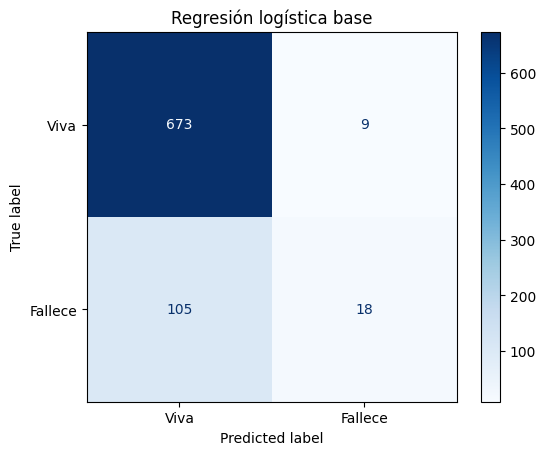

In [22]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = reglog_base.predict(X_test)    # ✏️

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Regresión logística base')
plt.show()

In [23]:
# Hiperparámetros a optimizar
rejilla_reglog = {
    "modelo__C":            [0.01, 0.1, 1, 10, 100],
    "modelo__l1_ratio":     [0, 0.5, 1],             # 0 = L2 · 0.5 = mezcla · 1 = L1  ✏️
    "modelo__class_weight": [None, 'balanced'],    # ✏️
}
# 5 × 3 × 2 = 30 combinaciones

In [24]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(reglog_base, rejilla_reglog, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_    # ✏️
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.856  {'modelo__C': 10, 'modelo__class_weight': None, 'modelo__l1_ratio': 0}
precision >> 0.684  {'modelo__C': 0.01, 'modelo__class_weight': None, 'modelo__l1_ratio': 0}
recall >> 0.643  {'modelo__C': 1, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 0}


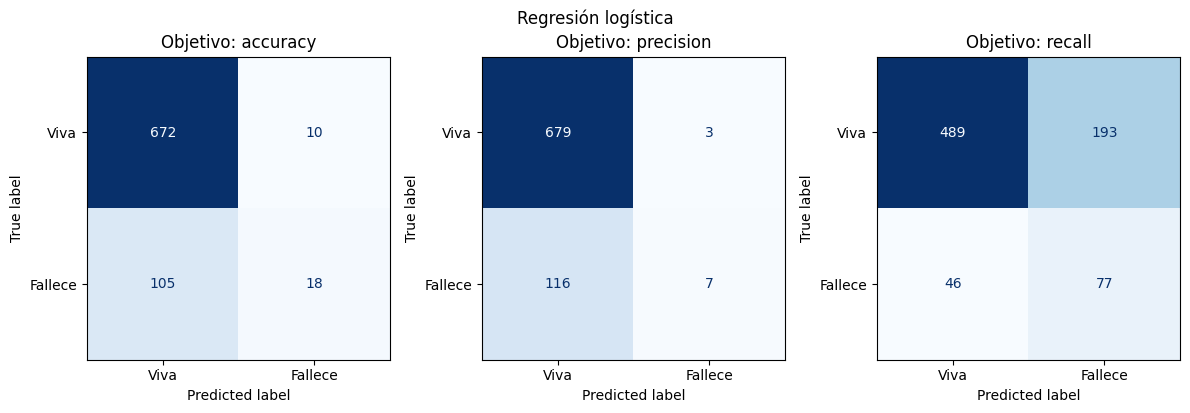

In [25]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))      # 1 fila con 3 recuadros

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Regresión logística')
plt.tight_layout()
plt.show()

In [26]:
# Guardando como finalista la versión optimizada con recall
finalistas['Regresión logística'] = mejores_modelos['recall']    # ✏️

---
## 6 · Naïve Bayes  *(7 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`var_smoothing`** | Suma una pequeña cantidad a las varianzas para que ninguna sea casi cero. Valores grandes = modelo más "suavizado" | 10 valores entre 10⁻⁹ y 1, generados con `np.logspace(-9, 0, 10)` |
| **`priors`** | Probabilidad inicial que el modelo asume para cada clase, en el orden `[viva, fallece]`. `None` = la proporción de los datos | `None` · `[0.5, 0.5]` · `[0.3, 0.7]` |

In [27]:
# Importando el modelo
from sklearn.naive_bayes import GaussianNB

# Pipeline: preprocesar → modelo
nb_base = Pipeline([
    ("prep",   preprocesador),
    ("modelo", GaussianNB())    # ✏️
])

# Ajustando el modelo con valores por defecto
nb_base.fit(X_train, y_train)

,steps,"[('prep', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


              precision    recall  f1-score   support

        Viva       0.89      0.84      0.86       682
     Fallece       0.32      0.41      0.36       123

    accuracy                           0.78       805
   macro avg       0.60      0.63      0.61       805
weighted avg       0.80      0.78      0.79       805



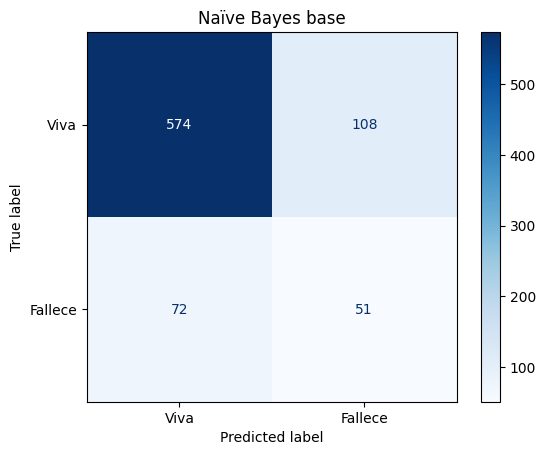

In [28]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = nb_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))    # ✏️

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Naïve Bayes base')
plt.show()

In [37]:
# Hiperparámetros a optimizar
rejilla_nb = {
    "modelo__var_smoothing": np.logspace(-9, 0, 10),               # 10 valores: 1e-9, 1e-8, …, 1  ✏️
    "modelo__priors":        [None, [0.5, 0.5], [0.5, 0.5]],        # [viva, fallece]  ✏️
}
# 10 × 3 = 30 combinaciones

In [38]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(nb_base, rejilla_nb, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.847  {'modelo__priors': None, 'modelo__var_smoothing': np.float64(1.0)}
precision >> 0.516  {'modelo__priors': None, 'modelo__var_smoothing': np.float64(1.0)}
recall >> 0.459  {'modelo__priors': [0.5, 0.5], 'modelo__var_smoothing': np.float64(0.01)}


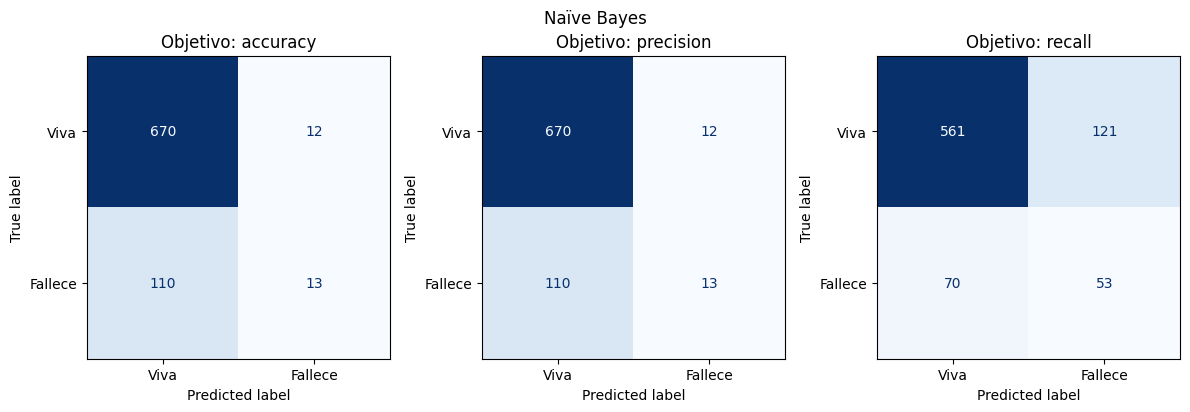

In [39]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Naïve Bayes')
plt.tight_layout()
plt.show()

In [40]:
# Guardando como finalista la versión optimizada con recall
finalistas['Naïve Bayes'] = mejores_modelos['recall']

---
## 7 · Máquinas de vectores de soporte (SVM)  *(7 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`kernel`** | La forma de la frontera: `"linear"` = recta · `"rbf"` = curvas suaves · `"poly"` = curva polinomial | los tres |
| **`C`** | Qué tanto castiga los errores en entrenamiento: `C` grande = frontera más ajustada (riesgo de sobreajuste) | 0.01 · 0.1 · 1 · 10 · 100 |
| **`gamma`** *(solo rbf)* | Qué tan "local" es la influencia de cada paciente | `"scale"` · 0.01 · 0.1 |
| **`degree`** *(solo poly)* | Grado del polinomio: 2 = parábola, 3 = cúbica | 2 · 3 |
| **`class_weight`** | `"balanced"` da más peso a las pacientes que fallecen | `None` · `"balanced"` |

Como cada kernel usa hiperparámetros distintos, la rejilla es una **lista de diccionarios** (uno por kernel).

⏱️ Con 4,000 pacientes esta búsqueda tarda **varios minutos**. Mientras corre, puedes avanzar leyendo las secciones siguientes.

> 🆕 **`max_iter=1_000_000`** es un **tope de iteraciones**, no un hiperparámetro que vayamos a optimizar. Con estos datos, la combinación `kernel="linear"` + `C=100` tarda **~5 minutos por pliegue** en converger (los datos se traslapan mucho y la SVM "pelea" por acomodar cada punto). El tope la detiene a tiempo para que la búsqueda completa tarde minutos y no media hora. Si aparece un aviso `ConvergenceWarning`, es normal: corresponde a esa combinación.

In [41]:
# Importando el modelo
from sklearn.svm import SVC

# Pipeline: preprocesar → modelo
svm_base = Pipeline([
    ("prep",   preprocesador),
    ("modelo", SVC(max_iter=1_000_000))    # tope de iteraciones (ver nota arriba)  ✏️
])

# Ajustando el modelo con valores por defecto
svm_base.fit(X_train, y_train)

,steps,"[('prep', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


              precision    recall  f1-score   support

        Viva       0.86      1.00      0.92       682
     Fallece       0.73      0.07      0.12       123

    accuracy                           0.85       805
   macro avg       0.79      0.53      0.52       805
weighted avg       0.84      0.85      0.80       805



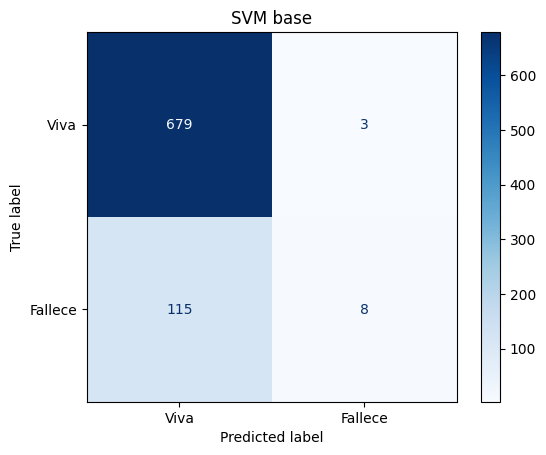

In [42]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = svm_base.predict(X_test)    # ✏️

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('SVM base')
plt.show()

In [43]:
# Hiperparámetros a optimizar
valores_C = [0.01, 0.1, 1, 10, 100]

rejilla_svm = [
    {"modelo__kernel":       ["linear"],
     "modelo__C":            valores_C,
     "modelo__class_weight": [None, "balanced"]},

    {"modelo__kernel":       ['rbf'],    # ✏️
     "modelo__C":            valores_C,
     "modelo__gamma":        ["scale", 0.01, 0.1],
     "modelo__class_weight": [None, "balanced"]},

    {"modelo__kernel":       ["poly"],
     "modelo__C":            valores_C,
     'modelo__gamma':     [2, 3],                      # grado del polinomio  ✏️
     "modelo__class_weight": [None, "balanced"]},
]
# 10 + 30 + 20 = 60 combinaciones

In [44]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(svm_base, rejilla_svm, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.852  {'modelo__C': 1, 'modelo__class_weight': None, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}
precision >> 0.788  {'modelo__C': 10, 'modelo__class_weight': None, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}
recall >> 0.629  {'modelo__C': 0.1, 'modelo__class_weight': 'balanced', 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}


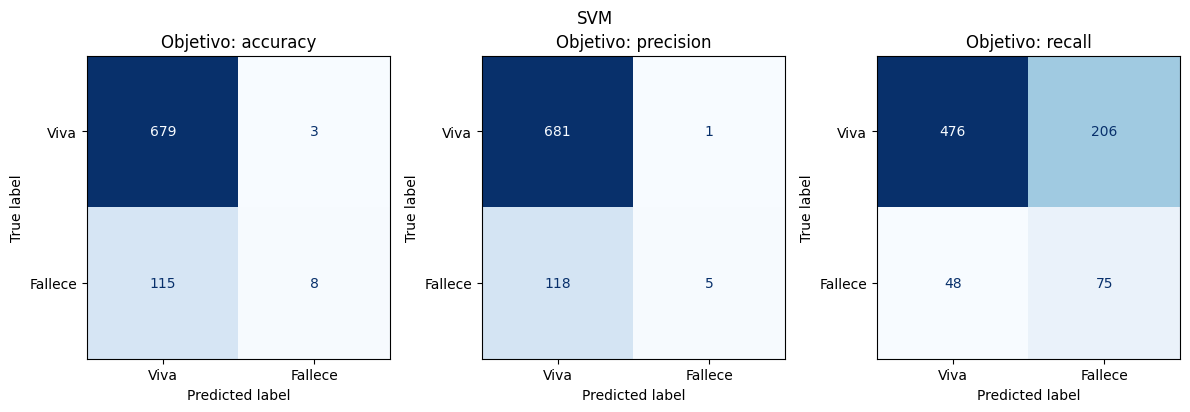

In [45]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('SVM')
plt.tight_layout()
plt.show()

In [46]:
# Guardando como finalista la versión optimizada con recall
finalistas['SVM'] = mejores_modelos['recall']

---
## 8 · Árbol de decisión y Random Forest  *(7 + 7 puntos)*

Los árboles **no necesitan escalar**: solo hacen preguntas del tipo *"¿`Tumor Size` ≤ 32?"*, y la respuesta es la misma en cualquier escala. Pero **sí necesitan el one-hot**, porque scikit-learn no acepta texto. Como el one-hot ya se aplicó a `X` en la sección 3, aquí usamos `X_train` **directamente, sin Pipeline**, y los nombres de la rejilla van **sin** el prefijo `modelo__` (igual que en la tarea).

### 8.1 Árbol de decisión

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`max_depth`** | Cuántas preguntas seguidas puede hacer (los "pisos" del árbol). `None` = sin límite | 2 · 3 · 4 · 5 · 6 · `None` |
| **`min_samples_leaf`** | Mínimo de pacientes en cada hoja | 1 · 5 · 10 |
| **`min_samples_split`** | Mínimo de pacientes que debe tener un nodo para **poder dividirse** | 2 · 10 · 20 |
| **`criterion`** | Fórmula que mide qué tan "revuelto" queda un grupo | `"gini"` · `"entropy"` |
| **`class_weight`** | `"balanced"` da más peso a las pacientes que fallecen | `None` · `"balanced"` |

In [47]:
# Importando el modelo y la función para dibujarlo
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Creando y ajustando el árbol con valores por defecto (sin Pipeline: no hace falta escalar)
arbol_base = DecisionTreeClassifier(random_state=42)    # ✏️
arbol_base.fit(X_train, y_train)

print('Pisos (profundidad):        ', arbol_base.get_depth())
print('Hojas (decisiones finales): ', arbol_base.get_n_leaves())

Pisos (profundidad):         26
Hojas (decisiones finales):  627


              precision    recall  f1-score   support

        Viva       0.86      0.83      0.85       682
     Fallece       0.22      0.27      0.24       123

    accuracy                           0.74       805
   macro avg       0.54      0.55      0.54       805
weighted avg       0.76      0.74      0.75       805



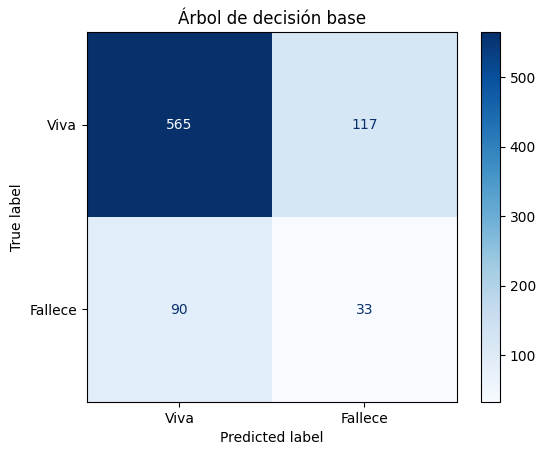

In [48]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = arbol_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')    # ✏️
plt.title('Árbol de decisión base')
plt.show()

In [49]:
# Hiperparámetros a optimizar (sin el prefijo modelo__ porque no hay Pipeline)
rejilla_arbol = {
    "max_depth":         [2, 3, 4, 5, 6, None],        # None = sin límite
    "min_samples_leaf":  [1, 5, 10],
    'min_samples_split': [2, 10, 20],    # ✏️
    "criterion":         ["gini", 'entropy'],    # ✏️
    "class_weight":      [None, "balanced"],
}
# 6 × 3 × 3 × 2 × 2 = 216 combinaciones (muchas, pero cada árbol tarda milisegundos)

In [50]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(arbol_base, rejilla_arbol, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.853  {'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
precision >> 0.579  {'class_weight': None, 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10, 'min_samples_split': 2}
recall >> 0.601  {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}


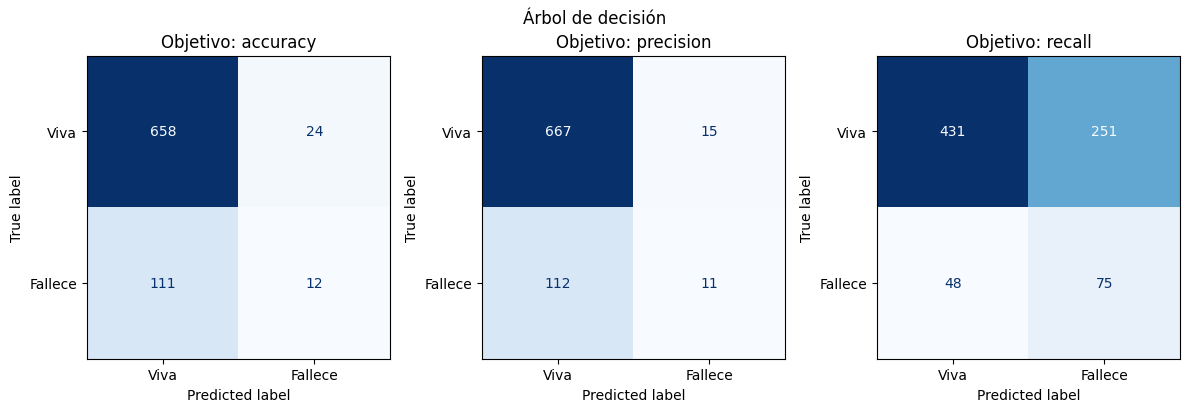

In [51]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Árbol de decisión')
plt.tight_layout()
plt.show()

In [52]:
# Guardando como finalista la versión optimizada con recall
finalistas['Árbol de decisión'] = mejores_modelos['recall']

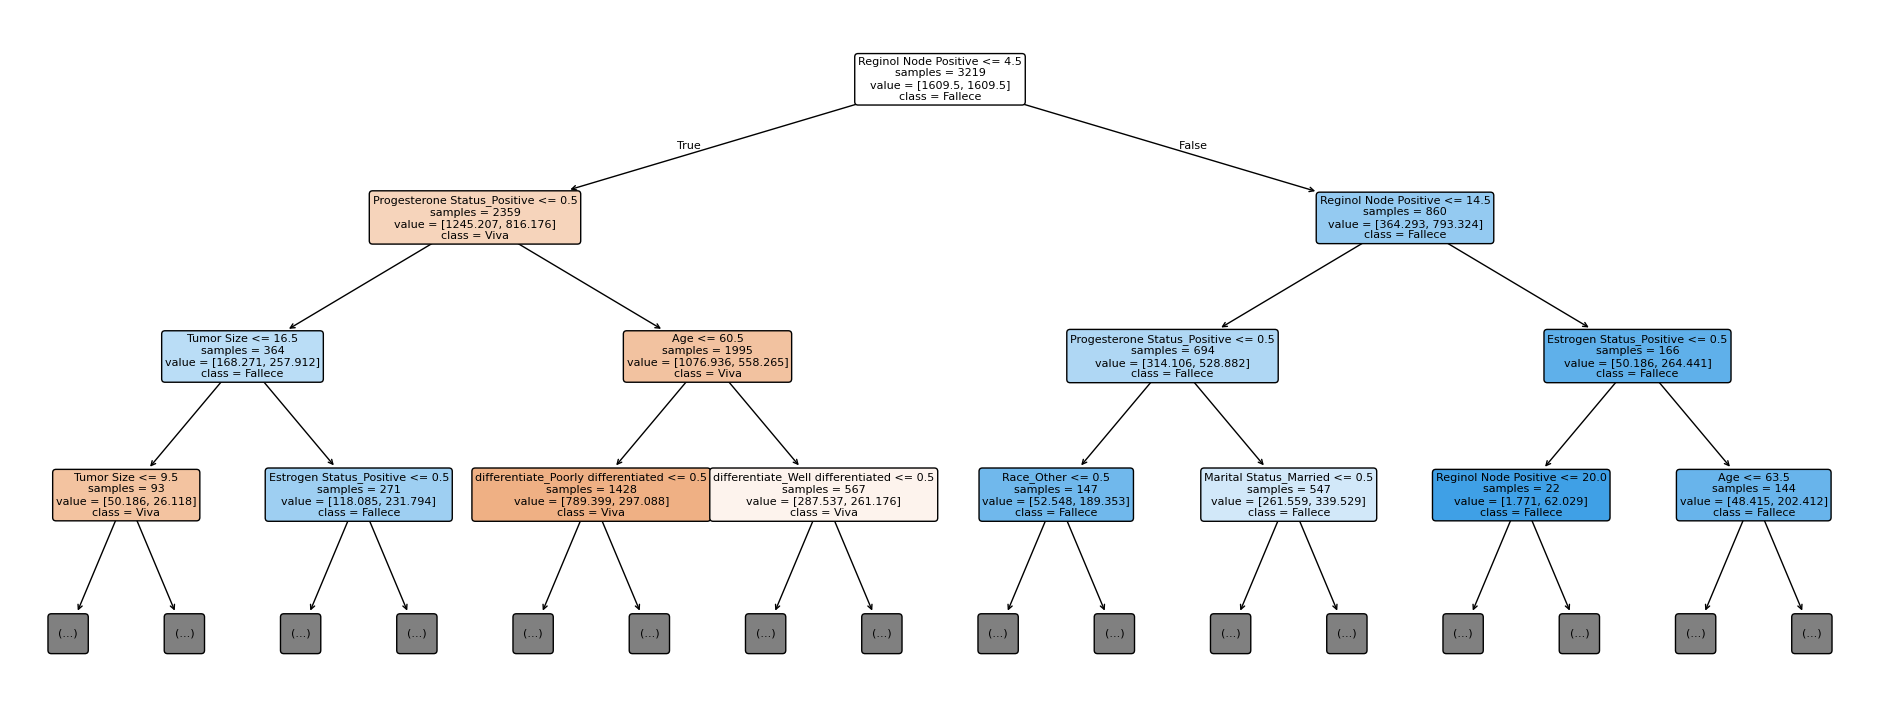

In [53]:
# Dibujando solo los primeros 3 pisos del árbol finalista (completo no cabría en pantalla)
plt.figure(figsize=(24, 9))
plot_tree(finalistas['Árbol de decisión'], feature_names=X.columns, class_names=clases,
          filled=True, rounded=True, impurity=False, max_depth=3, fontsize=8)    # ✏️
plt.show()

> Si el árbol finalista usa `class_weight="balanced"`, los números de `value` son **pacientes ponderadas** (cada paciente que fallece "vale" más que una que sigue viva), por eso no son enteros. Las cajas **azules** votan *Fallece* y las **naranjas** *Viva*; entre más intenso el color, más seguro está el árbol. Observa que las preguntas también usan las columnas del **one-hot**: por ejemplo, `Progesterone Status_Positive <= 0.5` significa *"¿el tumor **no** tiene receptores de progesterona?"*.

### 8.2 Random Forest

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`n_estimators`** | Cuántos árboles votan | 100 · 300 |
| **`max_features`** | Entre cuántas variables al azar elige cada árbol en cada pregunta. Con 25 columnas: `"sqrt"` → 5 · `"log2"` → 4 | `"sqrt"` · `"log2"` |
| **`max_depth`** | Igual que en el árbol | 5 · `None` |
| **`min_samples_leaf`** | Mínimo de pacientes en cada hoja de cada árbol | 1 · 3 |
| **`class_weight`** | `"balanced"` da más peso a las pacientes que fallecen | `None` · `"balanced"` |

⏱️ Esta búsqueda también tarda unos **minutos**: cada combinación entrena cientos de árboles. Ten paciencia.

In [55]:
# Importando el modelo
from sklearn.ensemble import RandomForestClassifier

# Creando y ajustando el bosque con valores por defecto
bosque_base = RandomForestClassifier(random_state=42)    # ✏️
bosque_base.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


              precision    recall  f1-score   support

        Viva       0.86      0.97      0.91       682
     Fallece       0.38      0.11      0.17       123

    accuracy                           0.84       805
   macro avg       0.62      0.54      0.54       805
weighted avg       0.78      0.84      0.80       805



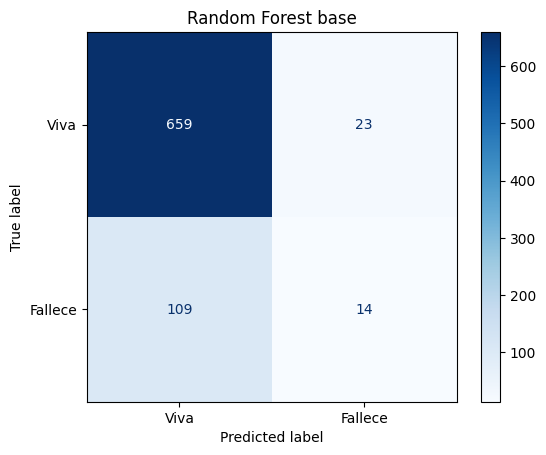

In [56]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = bosque_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))    # ✏️

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Random Forest base')
plt.show()

In [57]:
# Hiperparámetros a optimizar
rejilla_bosque = {
    "n_estimators":     [100, 300],
    "max_features":     ["sqrt", 4],            # 5 o 4 columnas al azar  ✏️
    "max_depth":        [5, None],
    'min_samples_leaf': [1, 3],    # ✏️
    "class_weight":     [None, "balanced"],
}
# 2 × 2 × 2 × 2 × 2 = 32 combinaciones

In [58]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(bosque_base, rejilla_bosque, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.854  {'class_weight': None, 'max_depth': None, 'max_features': 4, 'min_samples_leaf': 3, 'n_estimators': 300}
precision >> 0.675  {'class_weight': None, 'max_depth': 5, 'max_features': 4, 'min_samples_leaf': 1, 'n_estimators': 100}
recall >> 0.550  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 4, 'min_samples_leaf': 3, 'n_estimators': 100}


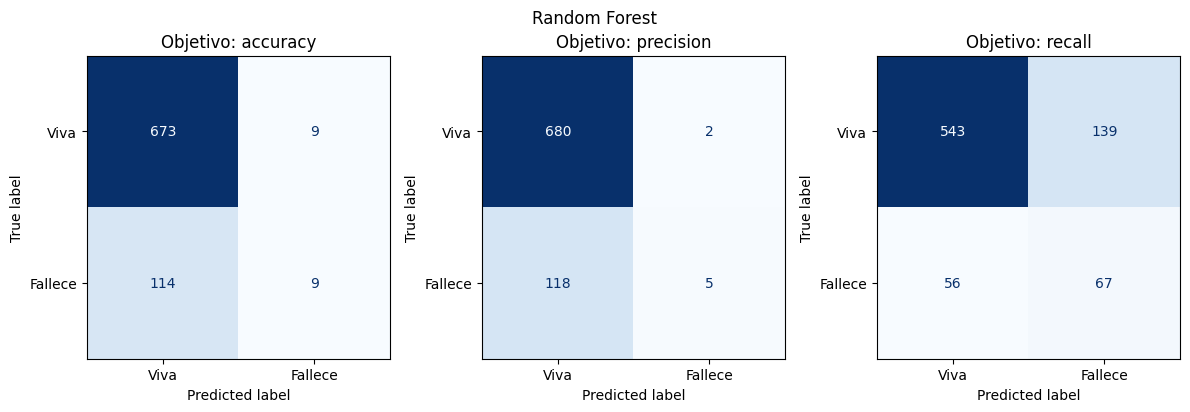

In [59]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Random Forest')
plt.tight_layout()
plt.show()

In [60]:
# Guardando como finalista la versión optimizada con recall
finalistas['Random Forest'] = mejores_modelos['recall']

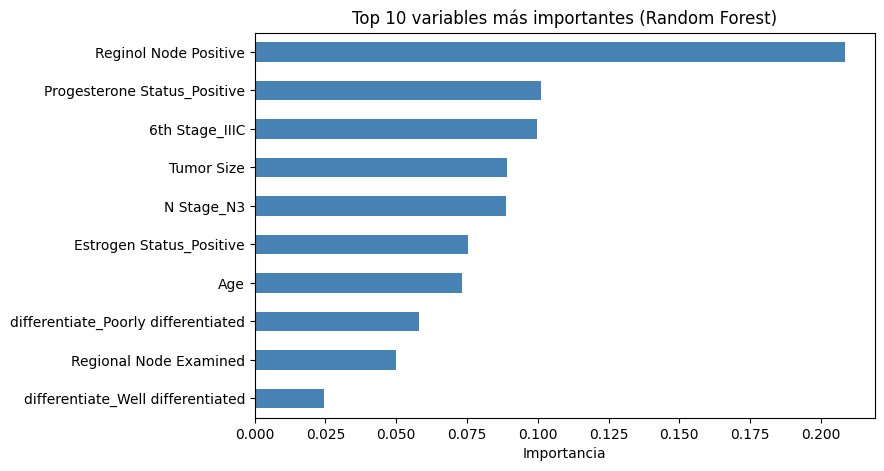

In [61]:
# ¿Qué columnas usó más el bosque para decidir?
importancias = pd.Series(finalistas['Random Forest'].feature_importances_, index=X.columns)    # ✏️

importancias.sort_values().tail(10).plot.barh(figsize=(8, 5), color='steelblue')
plt.title('Top 10 variables más importantes (Random Forest)')
plt.xlabel('Importancia')
plt.show()

---
## 9 · Comparación final de los cinco finalistas  *(6 puntos)*

Ahora comparamos los 5 finalistas **con las mismas pacientes de prueba**. Completa las fórmulas de sensibilidad y especificidad usando VP, VN, FP y FN.

La tabla queda ordenada de **menos FN a más FN** (y, si hay empate, de menos FP a más FP).

In [62]:
filas = []

for nombre, modelo in finalistas.items():
    y_pred = modelo.predict(X_test)
    vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()      # los 4 números de la matriz
    filas.append({
        'Modelo':        nombre,
        'Exactitud':     (vp + vn) / len(y_test),
        'Sensibilidad':  vp / (vp + fn),             # de las que fallecieron, ¿a cuántas detecta?  ✏️
        'Especificidad': vn / (vn + fp),             # de las que siguen vivas, ¿a cuántas descarta bien?  ✏️
        'FN':            fn,
        'FP':            fp,
    })

tabla = pd.DataFrame(filas).sort_values(by=['FN', 'FP'])
tabla.round(3)

,Modelo,Exactitud,Sensibilidad,Especificidad,FN,FP
0,Regresión logística,0.703,0.626,0.717,46,193
2,SVM,0.684,0.610,0.698,48,206
3,Árbol de decisión,0.629,0.610,0.632,48,251
4,Random Forest,0.758,0.545,0.796,56,139
1,Naïve Bayes,0.763,0.431,0.823,70,121


---
## 10 · Ajuste del umbral de decisión  *(6 puntos)*

Por defecto, los modelos dicen **"Fallece"** cuando la probabilidad de fallecer es **≥ 0.5**. Si **bajamos el umbral**, el modelo se vuelve más "desconfiado": detecta a más pacientes de alto riesgo (**menos FN**), a cambio de más falsas alarmas (**más FP**).

Lo probaremos con la **regresión logística** y el **Random Forest**, que calculan probabilidades con `predict_proba`. (La SVM no las calcula por defecto.)

In [63]:
umbrales = [0.5, 0.4, 0.3, 0.2, 0.1]

for nombre in ['Regresión logística', 'Random Forest']:
    proba = finalistas[nombre].predict_proba(X_test)[:, 1]      # columna 1 = probabilidad de "Fallece"  ✏️
    print(nombre)

    for umbral in umbrales:
        y_pred_u = (proba >= umbral).astype(int)                # 1 si supera el umbral, 0 si no  ✏️
        vn, fp, fn, vp = confusion_matrix(y_test, y_pred_u).ravel()
        print(f'   umbral {umbral}:   FN = {fn}   FP = {fp}')
    print()

Regresión logística
   umbral 0.5:   FN = 46   FP = 193
   umbral 0.4:   FN = 28   FP = 311
   umbral 0.3:   FN = 15   FP = 436
   umbral 0.2:   FN = 4   FP = 594
   umbral 0.1:   FN = 0   FP = 679

Random Forest
   umbral 0.5:   FN = 56   FP = 139
   umbral 0.4:   FN = 30   FP = 330
   umbral 0.3:   FN = 5   FP = 569
   umbral 0.2:   FN = 0   FP = 682
   umbral 0.1:   FN = 0   FP = 682



---
## 11 · Reflexión: ¿cuál es el mejor modelo?  *(30 puntos)*

Responde con tus propias palabras y **apóyate en los números** que obtuviste (matrices, tabla de la sección 9 y umbrales de la sección 10). No basta con decir "es mejor": explica **por qué**.

**Pregunta 1 · Falsos negativos vs. falsos positivos** *(7 pts)*
En este problema, ¿qué significa clínicamente un **falso negativo**? Describe qué le pasaría a esa paciente y compáralo con lo que le pasaría a una paciente con un **falso positivo**. ¿Cuál de los dos errores es más costoso y por qué?

✍️ **Tu respuesta:**

Un falso negativo pasa cuando el modelo considera como viva a una paciente que fallecio. Esto genera una falsa sensacion de seguridad en el paciente y hacer que no tenga el tratamiento adecuado. Un falso positivo pasa cuando se predice que una paciente va a morir, aunque va a sobrevivir, lo que puede generar preocupacion y tratamientos inecesarios. El falso negativo es mas costoso, porque ocasiona que no se identifique a una paciente de alto riesgo. Por ejemplo en la regresion logistica tuvo 46 falsos negativos y 193 falsos positivos.

**Pregunta 2 · ¿Con qué métrica optimizar?** *(6 pts)*
Elige uno de los modelos y compara sus matrices de confusión con objetivo `precision` y con objetivo `recall`. ¿Qué pasó con los FN y con los FP? ¿Por qué optimizar la precisión **no** es buena idea en este contexto?

✍️ **Tu respuesta:**

Elegi Random Forest para comparar los resultados. Con precision, el modelo tuvo 118 falsos negativos y 2 falsos positivos. Con recall, los falsos negativos disminuyeron a 56, aunque los falsos positivos aumentaron a 139.
Optimizar la precision no es lo conveniente en este problema, porque el modelo deja sin identificar a muchas pacientes que realmente fallecieron. Es mejor priorizar el recall, ya que detecta a mas pacientes de alto riesgo, aunque se tenga mas falsos positivos.

**Pregunta 3 · El mejor modelo** *(10 pts)*
Con la tabla de la sección 9, ¿cuál fue tu **mejor modelo**? Justifica tu elección con **al menos tres números** (FN, FP, sensibilidad, especificidad…). Si dos modelos empataron o quedaron muy cerca en FN, explica cómo desempataste.

✍️ **Tu respuesta:**

La regresion logistica fue el mejor modelo, porque obtuvo 46 falsos negativos, una sensibilidad de 0.626 y una especificidad de 0.717. Aunque su exactitud fue de 0.703, pudo identificar una mayor parte de pacientes fallecidas.

**Pregunta 4 · ¿Por qué no basta la exactitud?** *(3 pts)*
¿Por qué la exactitud por sí sola no es suficiente para elegir el modelo en este problema? *Pista:* piensa en la proporción de pacientes vivas y fallecidas, y en qué te dice (o no) la exactitud sobre el **tipo** de error.

✍️ **Tu respuesta:**

La exactitud no es suficiente porque existen mas pacientes vivas que fallecidas, por lo que el modelo puede obtener un buen resultado simplemente identificando correctamente a la mayoría de las pacientes vivas.
Por ejemplo, Naive Bayes obtuvo la mayor exactitud con 0.763, pero presento 70 falsos negativos y una sensibilidad de apenas 0.431.

**Pregunta 5 · Umbral y uso real** *(4 pts)*
Según la sección 10, ¿qué umbral recomendarías y cuántos FN y FP tendrías con él? ¿Usarías este modelo para **reemplazar** la decisión del oncólogo o solo como **apoyo**? Menciona una limitación de este estudio.

✍️ **Tu respuesta:**

Recomendaria la regresion logistica con un umbral de 0.4, porque con este valor se obtuvieron 28 falsos negativos y 311 falsos positivos. Comparado con el de 0.5, hay identificados de manera correcta a 18 pacientes fallecidas adicionales.
No utilizaria este modelo para reemplazar al oncologo, solo como una herramienta de apoyo para identificar pacientes que podrian necesitar mayor seguimiento y tratamiento. Una limitacion del estudio es que existe mucho desbalance entre pacientes vivas y fallecidas, lo que puede afectar la capacidad del modelo para reconocer a ambos grupos de forma correcta.